### **Color Spaces and Thresholding**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/01_Color_Spaces_and_Thresholding.ipynb)

> A color image is a stack of channels. OpenCV stores them as **BGR**, while Matplotlib and most libraries expect **RGB**, a frequent source of swapped colors. This notebook converts between color spaces (BGR, RGB, grayscale, HSV), splits channels, and segments the image with **manual**, **Otsu**, and **adaptive** thresholding.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [2]:
# Load the image (NASA public-domain photo, also available as skimage.data.astronaut)
img = load_image("astronaut.png")
print("Shape (height, width, channels):", img.shape, "| dtype:", img.dtype)

Shape (height, width, channels): (512, 512, 3) | dtype: uint8


#### **01. BGR, RGB, Grayscale, and HSV**

* **BGR** is OpenCV's channel order; showing it as if it were RGB swaps red and blue.
* **Grayscale** combines the channels with perceptual weights: `0.299 R + 0.587 G + 0.114 B`.
* **HSV** separates color (**hue**) from intensity (**value**), which makes color-based segmentation more robust to lighting.

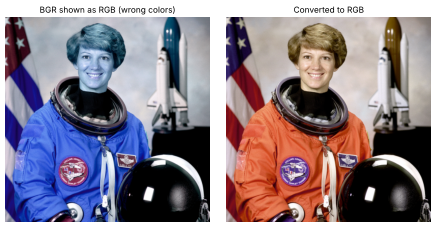

In [3]:
# Compare the wrong display (BGR shown as RGB) with the correct one
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img); axes[0].set_title("BGR shown as RGB (wrong colors)")
axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[1].set_title("Converted to RGB")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

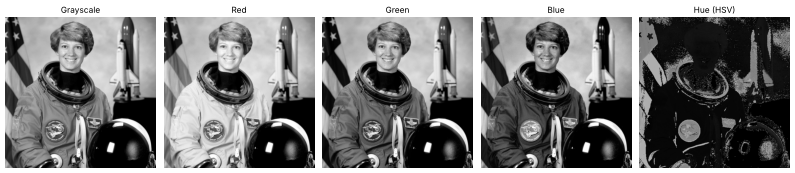

In [4]:
# Grayscale, individual channels, and the HSV hue channel
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
B, G, R = cv2.split(img)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
show([gray, R, G, B, hsv[:, :, 0]], ["Grayscale", "Red", "Green", "Blue", "Hue (HSV)"], size=(16, 4))

#### **02. Thresholding**

Thresholding turns a grayscale image into a binary mask: pixels above the threshold become white (255), the rest black (0).

* **Manual:** a fixed value chosen by the user.
* **Otsu:** picks the value that best separates the two peaks of the histogram (minimum within-class variance).
* **Adaptive:** computes a different threshold for each neighborhood, which handles uneven lighting.

Otsu threshold: 100


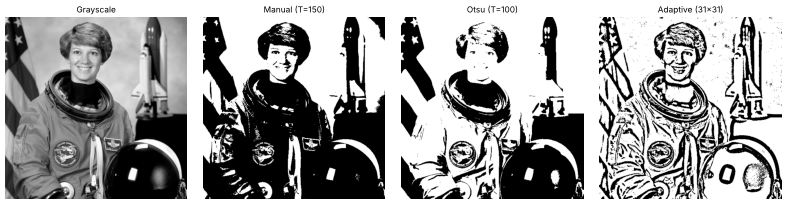

In [5]:
# Manual, Otsu, and adaptive thresholding
_, manual = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)
otsu_value, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 5)
print(f"Otsu threshold: {otsu_value:.0f}")
show([gray, manual, otsu, adaptive], ["Grayscale", "Manual (T=150)", f"Otsu (T={otsu_value:.0f})", "Adaptive (31x31)"], size=(16, 4))

#### **Key Takeaways**

* Convert BGR to RGB only for display; keep OpenCV's BGR order for processing.
* Otsu removes the guesswork of a manual threshold when the histogram has two clear groups.
* Adaptive thresholding works better when the lighting changes across the image.